In [18]:
# Install Python dependencies
#%pip install r5py geopandas shapely gtfs-kit matplotlib

# Verify Java 21+ is active (e.g., via SDKMAN, Homebrew, or apt)
#java -version

In [19]:
import os
# Ensure Java 21 is active before importing r5py
os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@21/libexec/openjdk.jdk/Contents/Home"

import datetime
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, box
from scipy.interpolate import griddata
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import gtfs_kit as gk
import r5py

In [33]:
# 1. Load Network & Pick a Central Bus Station
OSM_PBF = "../data/lusaka.osm.pbf"
GTFS_CURRENT = "../data/gtfs.zip"

routes_gdf = gpd.read_file("../data/processed_trips.geojson")

feed = gk.read_feed(GTFS_CURRENT, dist_units="km")
service_date = feed.get_first_week()[0]
DEPARTURE_DT = datetime.datetime.strptime(f"{service_date} 07:30:00", "%Y%m%d %H:%M:%S")

transport_network = r5py.TransportNetwork(OSM_PBF, [GTFS_CURRENT])

# Automatically find a central terminal in stops.txt (or hardcode Point(lon, lat))
stops_df = feed.stops.copy()
hub_match = stops_df[
    stops_df["stop_name"].str.contains("Kulima", case=False, na=False)
]
central_stop = hub_match.iloc[0] if not hub_match.empty else stops_df.iloc[0]
hub_name = central_stop["stop_name"]
HUB_POINT = Point(central_stop["stop_lon"], central_stop["stop_lat"])

origin_gdf = gpd.GeoDataFrame(
    {"id": ["central_hub"], "geometry": [HUB_POINT]}, crs="EPSG:4326"
)
print(f"Origin Hub: {hub_name} ({HUB_POINT.y:.4f}, {HUB_POINT.x:.4f})")

cutoffs = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

Origin Hub: Kulima Tower - Ben Bella Rd (-15.4254, 28.2799)


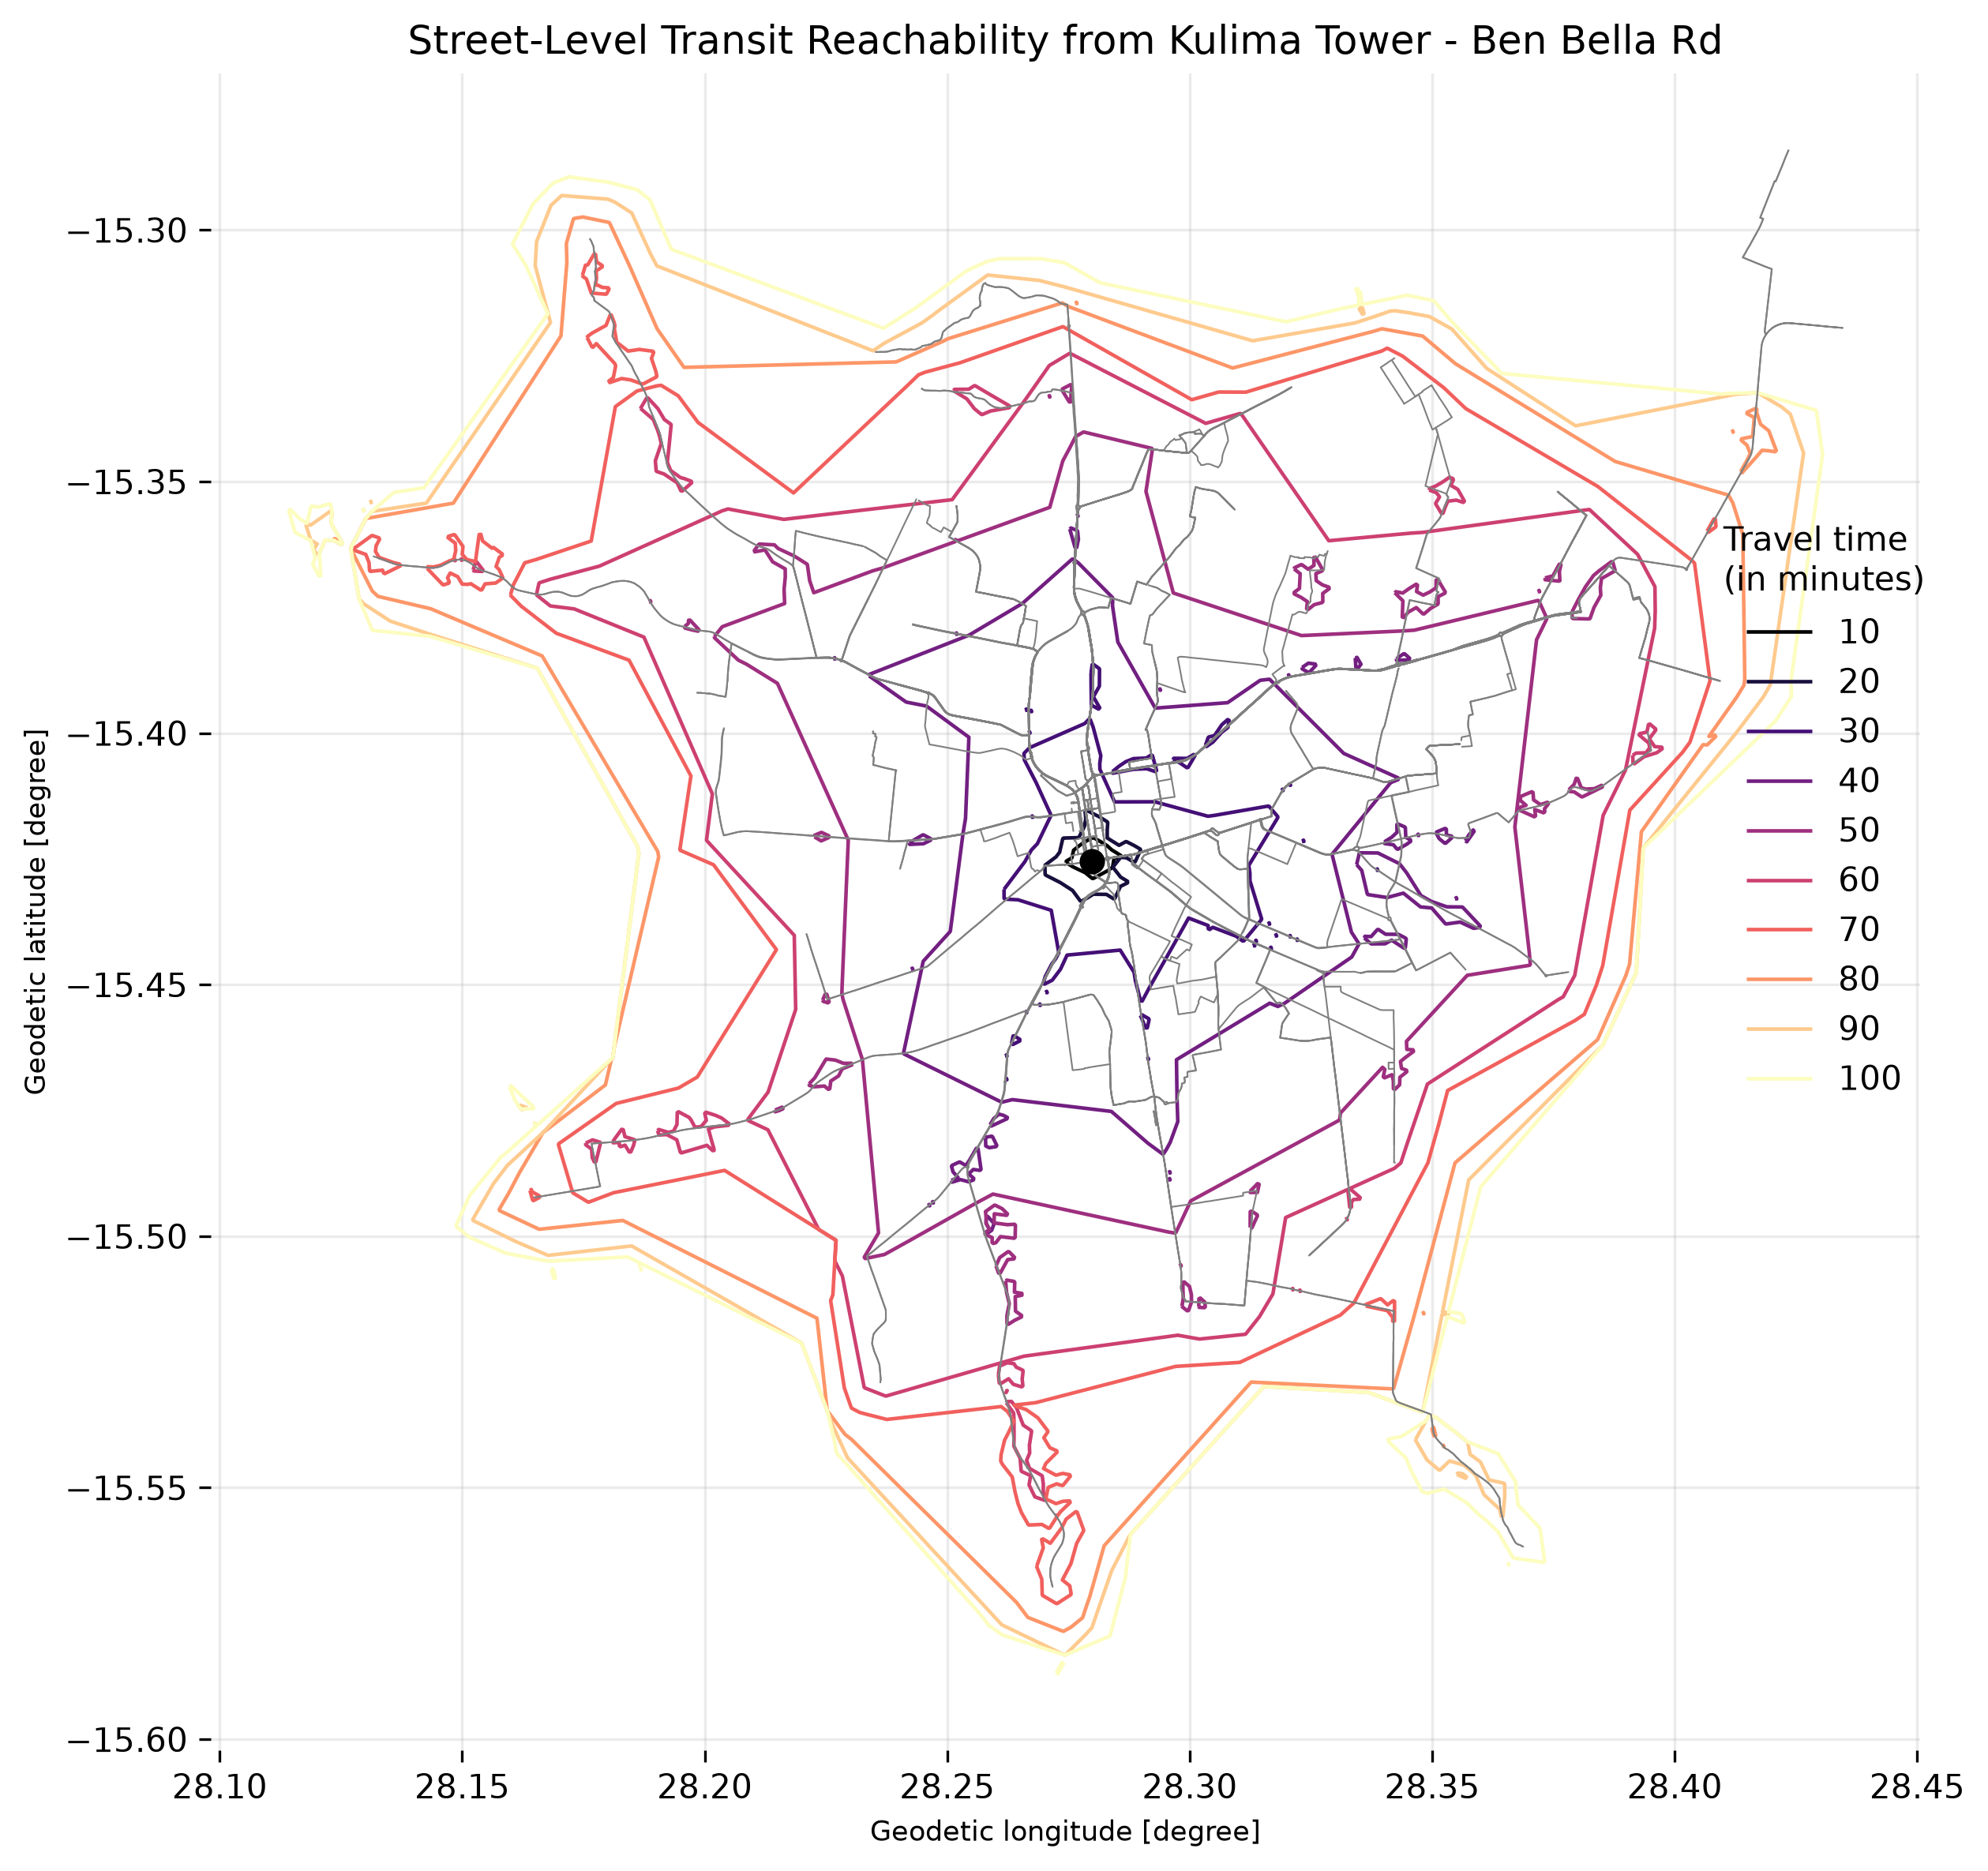

In [35]:
# 2. IMAGE 2: Street-Network Travel Time Map (r5py.Isochrones)
iso_lines = r5py.Isochrones(
    transport_network,
    origins=origin_gdf,
    departure=DEPARTURE_DT,
    departure_time_window=datetime.timedelta(minutes=30),
    transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
    isochrones=cutoffs,
)
iso_lines["minutes"] = (iso_lines["travel_time"].dt.total_seconds() / 60).astype(int)

# Plot from largest (100 min) to smallest (10 min) so shorter times draw on top
iso_lines = iso_lines.sort_values("minutes", ascending=False)

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
iso_lines.plot(
    column="minutes",
    cmap="magma",
    categorical=True,
    linewidth=1.1,
    legend=True,
    legend_kwds={"title": "Travel time\n(in minutes)", "bbox_to_anchor": (1.02, 0.75), "frameon": False},
    ax=ax,
)
origin_gdf.plot(ax=ax, color="black", markersize=45, zorder=10)
routes_gdf.plot(ax=ax, color="gray", linewidth=0.5,)
ax.set_title(f"Street-Level Transit Reachability from {hub_name}", fontsize=12)
ax.grid(True, linestyle="-", alpha=0.25)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
plt.tight_layout()
plt.savefig("map2_street_travel_times.png", dpi=300)
plt.show()

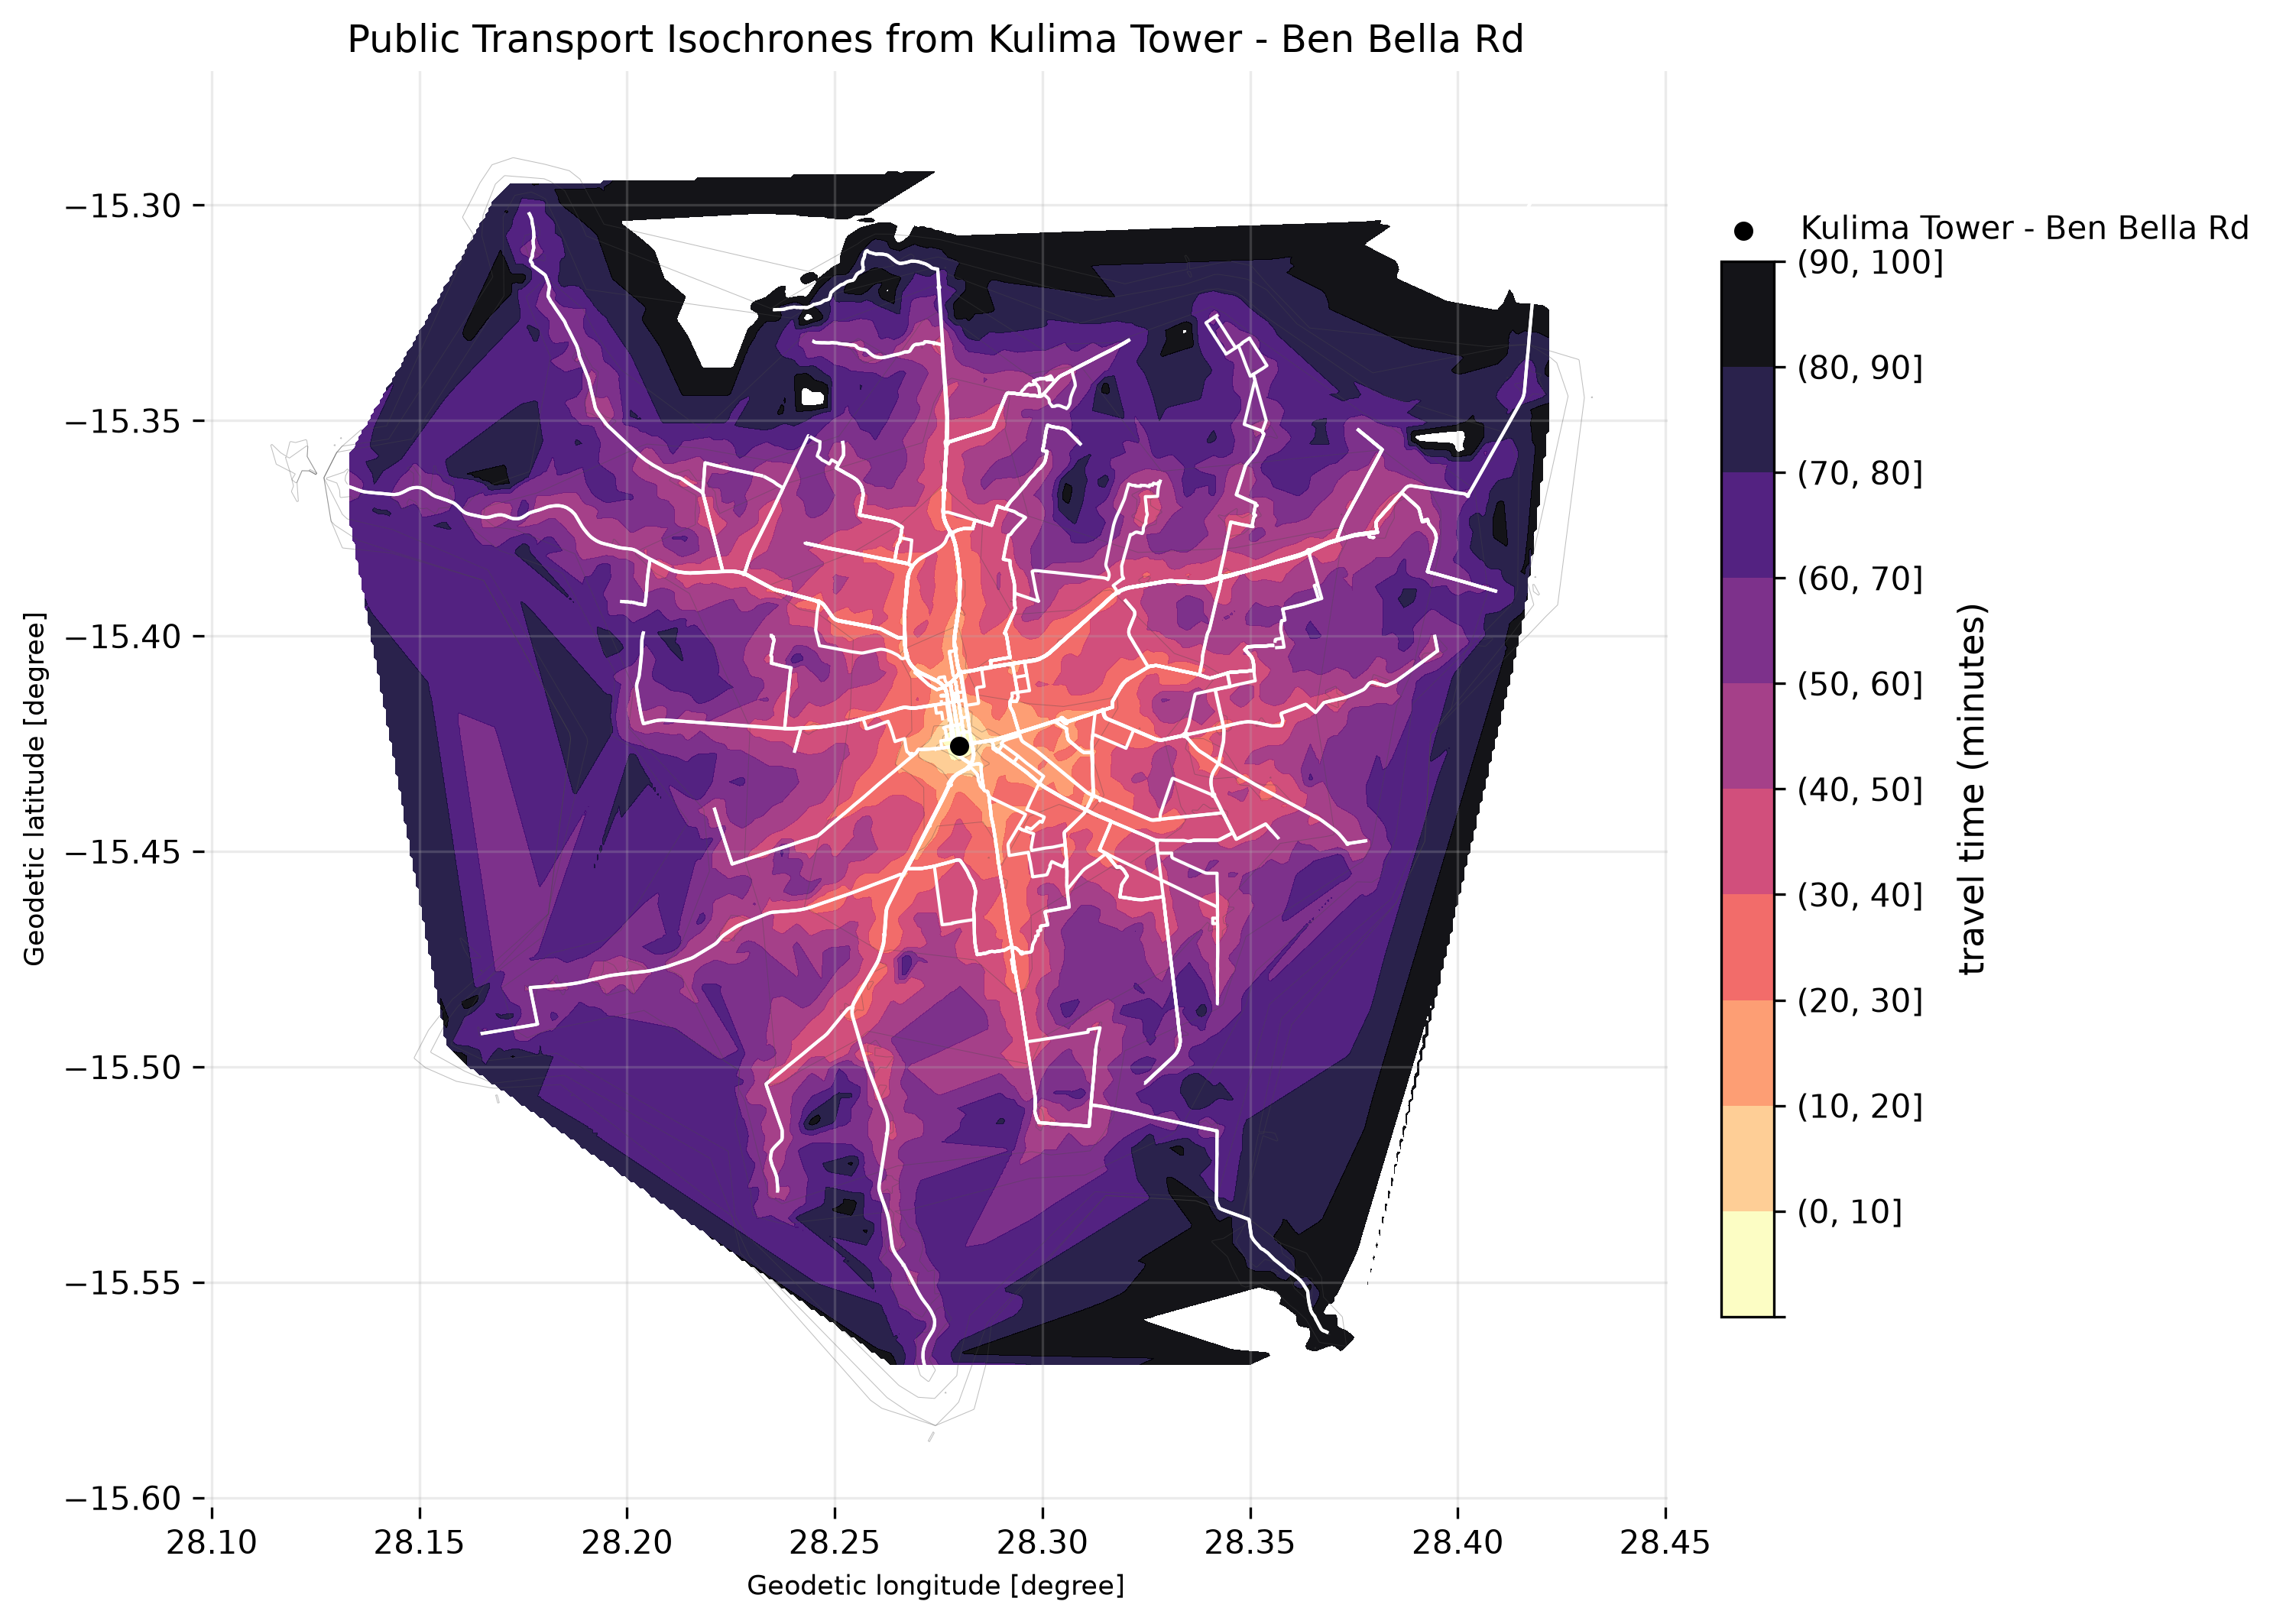

In [ ]:
# 3. IMAGE 1: Filled Polygon Isochrone Bands (TravelTimeMatrix)
# Build a fine 350m destination grid around the transit service area
stops_gdf = gpd.GeoDataFrame(
    stops_df,
    geometry=gpd.points_from_xy(stops_df["stop_lon"], stops_df["stop_lat"]),
    crs="EPSG:4326",
)
utm_crs = stops_gdf.estimate_utm_crs()
stops_utm = stops_gdf.to_crs(utm_crs)
minx, miny, maxx, maxy = stops_utm.total_bounds

step = 350  # 350m resolution for smooth contour bands
xs = np.arange(minx, maxx, step)
ys = np.arange(miny, maxy, step)
grid_pts = [Point(x, y) for x in xs for y in ys]
dest_utm = gpd.GeoDataFrame({"geometry": grid_pts}, crs=utm_crs)

# Keep points within 1 km of transit stops
service_hull = stops_utm.buffer(1000).union_all()
dest_utm = dest_utm[dest_utm.intersects(service_hull)].reset_index(drop=True)
dest_utm["id"] = dest_utm.index.astype(str)
dest_wgs84 = dest_utm.to_crs("EPSG:4326")

ttm = r5py.TravelTimeMatrix(
    transport_network,
    origins=origin_gdf,
    destinations=dest_wgs84,
    departure=DEPARTURE_DT,
    departure_time_window=datetime.timedelta(minutes=30),
    transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
    snap_to_network=True,
)

merged = dest_wgs84.merge(ttm, left_on="id", right_on="to_id").dropna(subset=["travel_time"])

# Interpolate irregular reachable points onto a regular 2D raster grid for contourf
xi = np.linspace(merged.geometry.x.min(), merged.geometry.x.max(), 400)
yi = np.linspace(merged.geometry.y.min(), merged.geometry.y.max(), 400)
XI, YI = np.meshgrid(xi, yi)

ZI = griddata(
    points=(merged.geometry.x.values, merged.geometry.y.values),
    values=merged["travel_time"].values,
    xi=(XI, YI),
    method="linear",
)

levels = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
cmap = plt.get_cmap("magma_r", len(levels) - 1)
norm = mcolors.BoundaryNorm(levels, cmap.N)

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

# Plot filled contour bands
cf = ax.contourf(XI, YI, ZI, levels=levels, cmap=cmap, norm=norm, alpha=0.92)

# Overlay subtle street network lines on top (like Image 1)
iso_lines.plot(ax=ax, color="#4a4a4a", linewidth=0.25, alpha=0.35)

# Plot central station marker
origin_gdf.plot(ax=ax, color="black", markersize=25, label=hub_name, zorder=10)
routes_gdf.plot(ax=ax, color="white", linewidth=1, zorder=5)

# Discrete interval colorbar matching (0, 10], (10, 20], ...
cbar = plt.colorbar(cf, ax=ax, shrink=0.65, pad=0.03, ticks=levels)
cbar.ax.set_yticklabels([""] + [f"({levels[i]}, {levels[i+1]}]" for i in range(len(levels) - 1)])
cbar.set_label("travel time (minutes)", fontsize=11)

ax.legend(loc="upper left", bbox_to_anchor=(1.01, 0.92), frameon=False)
ax.set_title(f"Public Transport Isochrones from {hub_name}", fontsize=12)
ax.grid(True, linestyle="-", alpha=0.25)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
plt.tight_layout()
plt.savefig("map1_isochrone_polygons.png", dpi=300)
plt.show()